# A VQE loop on Aer and on Maestro, both with MPS

This notebook runs the same variational loop twice: once with Qiskit Aer's `EstimatorV2` and once with `MaestroEstimator`, both on matrix product states with the same bond-dimension cap. It's a sanity check that switching estimators changes nothing but the import line and the run time. The two energy traces should lie on top of each other.

It isn't a benchmark. For controlled timings, see the [benchmarks page](https://qoroquantum.github.io/maestro/benchmarks.html) and `benchmarks/estimator_mps.py` in this repository.

Needs `pip install qiskit-maestro qiskit-aer matplotlib`.

In [1]:
# SPDX-FileCopyrightText: 2026 Qoro Quantum
# SPDX-License-Identifier: GPL-3.0-or-later

import platform
import time
from importlib import metadata

import matplotlib.pyplot as plt
import numpy as np
from qiskit.circuit.library import real_amplitudes
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

from qiskit_maestro import MaestroEstimator

print(platform.platform(), platform.machine())
for package in ("qiskit", "qiskit-aer", "qoro-maestro", "qiskit-maestro"):
    print(package, metadata.version(package))

macOS-26.6.2-arm64-arm-64bit arm64
qiskit 2.6.1
qiskit-aer 0.18.2
qoro-maestro 0.3.10
qiskit-maestro 0.1.0


## The problem

Find the ground-state energy of a 100-qubit transverse-field Ising chain, $H = -\sum_i Z_i Z_{i+1} - 0.7 \sum_i X_i$, with a linear `real_amplitudes` ansatz.

In [2]:
num_qubits = 100
hamiltonian = SparsePauliOp.from_sparse_list(
    [("ZZ", [q, q + 1], -1.0) for q in range(num_qubits - 1)]
    + [("X", [q], -0.7) for q in range(num_qubits)],
    num_qubits,
)
ansatz = real_amplitudes(num_qubits, reps=2, entanglement="linear")
print(f"{len(hamiltonian)} Hamiltonian terms, {ansatz.num_parameters} parameters")

199 Hamiltonian terms, 300 parameters


## The two estimators

Only the constructor differs. Maestro accepts Aer's `options` dictionary as is, so the options are written once.

In [3]:
options = {
    "backend_options": {
        "method": "matrix_product_state",
        "matrix_product_state_max_bond_dimension": 64,
        "matrix_product_state_truncation_threshold": 1e-10,
    }
}
estimators = {
    "Aer": AerEstimator(options=options),
    "Maestro": MaestroEstimator(options=options),
}

## The loop

Each iteration of SPSA makes one estimator call with three parameter sets: the current point, for the energy trace, and the two perturbed points that estimate the gradient. Both runs use the same random perturbations, so they follow the same path as long as the energies agree.

In [4]:
def spsa(estimator, iterations=40, seed=11):
    rng = np.random.default_rng(seed)
    theta = np.full(ansatz.num_parameters, 0.1)
    energies, seconds = [], []
    for k in range(iterations):
        a_k, c_k = 0.001 / (k + 1) ** 0.602, 0.05 / (k + 1) ** 0.101
        delta = rng.choice([-1.0, 1.0], size=theta.size)
        points = np.stack([theta, theta + c_k * delta, theta - c_k * delta])
        start = time.perf_counter()
        energy, plus, minus = estimator.run([(ansatz, hamiltonian, points)]).result()[0].data.evs
        seconds.append(time.perf_counter() - start)
        energies.append(energy)
        theta = theta - a_k * (plus - minus) / (2 * c_k) * delta
    return np.array(energies), np.array(seconds)


traces = {name: spsa(estimator) for name, estimator in estimators.items()}

(aer_e, aer_t), (maestro_e, maestro_t) = traces.values()
print(f"{'':10}{'total time':>12}{'per iteration':>15}{'final energy':>15}")
for name, (energies, seconds) in traces.items():
    print(f"{name:10}{seconds.sum():11.2f}s{np.median(seconds) * 1e3:12.1f} ms{energies[-1]:15.6f}")
print(f"\nLargest energy difference between the two runs: {np.max(np.abs(aer_e - maestro_e)):.1e}")
print(f"Speed-up of the whole loop: {aer_t.sum() / maestro_t.sum():.1f}x")

            total time  per iteration   final energy
Aer              3.12s        77.6 ms     -87.758389
Maestro          0.38s         9.2 ms     -87.758389

Largest energy difference between the two runs: 3.4e-09
Speed-up of the whole loop: 8.2x


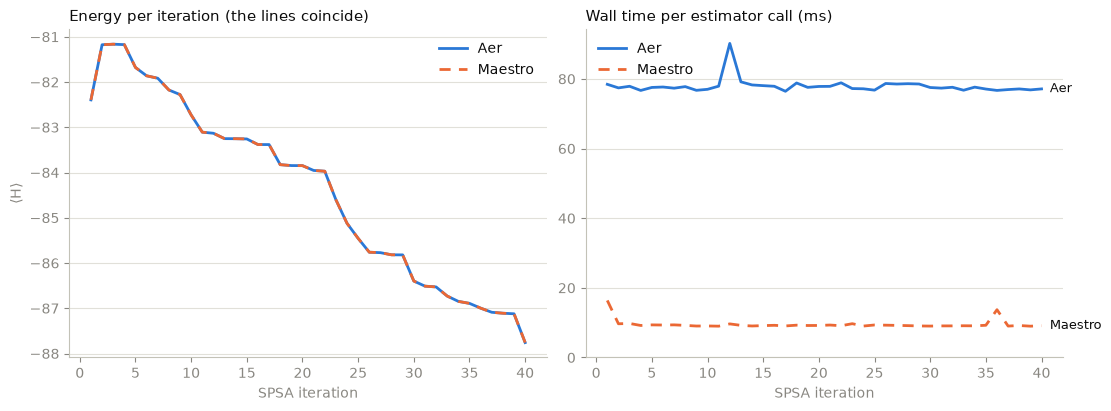

In [5]:
# Colours: the first two slots of a colour-blind-safe categorical palette.
colors = {"Aer": "#2a78d6", "Maestro": "#eb6834"}
styles = {"Aer": "-", "Maestro": (0, (4, 3))}
ink, muted, grid = "#0b0b0b", "#898781", "#e1e0d9"

fig, (ax_energy, ax_time) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
iterations = np.arange(1, len(aer_e) + 1)
for name, (energies, seconds) in traces.items():
    ax_energy.plot(
        iterations, energies, linestyle=styles[name], color=colors[name], lw=2, label=name
    )
    ax_time.plot(
        iterations, seconds * 1e3, linestyle=styles[name], color=colors[name], lw=2, label=name
    )
    ax_time.annotate(
        name,
        (iterations[-1], seconds[-1] * 1e3),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=ink,
        fontsize=9,
    )

ax_energy.set_title("Energy per iteration (the lines coincide)", loc="left", color=ink, fontsize=11)
ax_energy.set_ylabel("⟨H⟩", color=muted)
ax_time.set_title("Wall time per estimator call (ms)", loc="left", color=ink, fontsize=11)
ax_time.set_ylim(bottom=0)
for ax in (ax_energy, ax_time):
    ax.set_xlabel("SPSA iteration", color=muted)
    ax.grid(axis="y", color=grid, lw=0.8)
    ax.tick_params(colors=muted, labelcolor=muted)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c3c2b7")
    ax.legend(frameon=False, labelcolor=ink)
plt.show()

## What to look for

- The energy traces coincide. The largest difference printed above is around 1e-9, far smaller than the change from one iteration to the next, so the optimiser follows the same path on both.
- The time per call is the cost of three 100-qubit MPS energy evaluations of a 199-term Hamiltonian. Timings depend on your machine and its core count; rerun the notebook to see yours.